# @title 01. Pauli Collision Entropy and Smooth Min-Entropy
# Pauli Collision Entropy and Smooth Min-Entropy

Adapted from the supplied Werner notebook for
$$\rho_{XB}=\tfrac12\sum_{x=0}^1 |x\rangle\langle x|\otimes|\phi^x\rangle\langle\phi^x|,
\qquad |\phi^x\rangle=\sqrt p|0\rangle+(-1)^x\sqrt{1-p}|1\rangle.$$
The default is **p = 0.05**, as in
[Tomamichel and Hayashi, arXiv:1208.1478](https://arxiv.org/html/1208.1478#A1).

Edit the parameter lists in **Parameters and Solver Settings**, then run from
the top. This notebook focuses on measured smooth collision entropy and
smooth min-entropy with quantum side information. It includes baseline
validation, CSV checkpoints, collision-only plots, comparison plots, and
difference plots. Graph titles follow the supplied Werner notebook's style,
with the state parameter changed from W to p.

**Smoothing conventions:** epsilon is the linear penalty parameter in the
supplied measured-collision program. To retain its min-entropy comparison,
we use the purified-distance radius delta = sqrt(epsilon). The radius
and its square are stored explicitly in the min-entropy results;
entropy curves are not themselves secret-key lengths. One global smoothing
budget is used for all n copies.

Copy permutation symmetry reduces the collision matrix to size n+1.
The conditional pure states reduce smooth min-entropy to a scalar search.

**Google Colab:** run from the top and authorize the Drive mount. Generated
CSV and PNG files default to `/content/drive/MyDrive/pauli_entropy_results`.
Save the notebook itself using **File > Save a copy in Drive**. The setup
installs missing dependencies before importing CVXPY. A CPU runtime suffices.

In [1]:
# @title 02. Google Colab Setup and Google Drive Storage
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

# Edit these before running from the top. CLARABEL needs no license.
SAVE_TO_GOOGLE_DRIVE = True
DRIVE_RESULTS_DIR = '/content/drive/MyDrive/pauli_entropy_results'
INSTALL_MOSEK = True  # Also choose COLLISION_SOLVER='MOSEK' in the solver settings.
COLAB_MOSEK_LICENSE_PATH = '/content/drive/MyDrive/mosek.lic'
LOCAL_MOSEK_LICENSE_PATH = r'C:\Users\Cat\Downloads\UROPS\mosek.lic'

try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False

MOSEK_LICENSE_PATH = COLAB_MOSEK_LICENSE_PATH if IN_COLAB else LOCAL_MOSEK_LICENSE_PATH

if IN_COLAB:
    packages = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy',
                'matplotlib': 'matplotlib', 'cvxpy': 'cvxpy', 'clarabel': 'clarabel'}
    if INSTALL_MOSEK:
        packages['mosek'] = 'mosek'
    missing = [package for module, package in packages.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        cvxpy_already_loaded = 'cvxpy' in sys.modules
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
        if cvxpy_already_loaded:
            raise RuntimeError('Packages were installed after CVXPY was loaded. Restart the Colab session, then run all cells from the top.')
    if SAVE_TO_GOOGLE_DRIVE or INSTALL_MOSEK:
        from google.colab import drive
        drive.mount('/content/drive')

if Path(MOSEK_LICENSE_PATH).is_file():
    os.environ['MOSEKLM_LICENSE_FILE'] = MOSEK_LICENSE_PATH
    print('MOSEK license:', MOSEK_LICENSE_PATH)
elif IN_COLAB and INSTALL_MOSEK:
    raise FileNotFoundError(f'MOSEK license not found: {MOSEK_LICENSE_PATH}')

print('Environment:', 'Google Colab' if IN_COLAB else 'Local Python')


Mounted at /content/drive
MOSEK license: /content/drive/MyDrive/mosek.lic
Environment: Google Colab


In [2]:
# @title 03. Imports and Available Solvers
import hashlib
import itertools
import json
import math
import os
import time
import warnings
from pathlib import Path
from functools import lru_cache
from math import comb, lgamma
import numpy as np
import pandas as pd
import cvxpy as cp
import matplotlib.pyplot as plt
from scipy.special import gammaln, logsumexp
from scipy.stats import binom

# Required packages: numpy pandas cvxpy clarabel scipy matplotlib.
# MOSEK is optional; installation and license settings are in the preceding cell.
print('Available solvers:', cp.installed_solvers())
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})

Available solvers: ['CLARABEL', 'CVXOPT', 'GLPK', 'GLPK_MI', 'HIGHS', 'MOSEK', 'OSQP', 'SCIPY', 'SCS']


In [3]:
# @title 04. Parameters and Solver Settings
P_VALUES = [0.05]
COLLISION_EPSILON_VALUES = [0.1, 0.01, 0.001, 0.0001, 0.00001, 0.0]
MIN_ENTROPY_EPSILON_VALUES = list(COLLISION_EPSILON_VALUES)
n = 100
COLLISION_N_VALUES = list(range(1, n+1))
MIN_ENTROPY_N_VALUES = list(range(1, n+1))
COLLISION_SOLVER = 'MOSEK'  # Alternatively MOSEK (with a license) or SCS
COLLISION_TOL = 1e-5
MAX_COLLISION_COPIES = 100  # Numerical guard for the n+1 matrix; increase after checking residuals
MAX_BASELINE_COPIES = 2  # Full exponential matrices are used only for validation
MAX_SCALAR_MIN_COPIES = 100  # Guard against loss of objective precision
SOLVER_VERBOSE = False
RESUME = True
CONTINUE_ON_ERROR = False
RUN_VALIDATION = True  # Enable after changing a formulation; avoids repeated baseline SDPs
VALIDATION_N_VALUES = [1, 2]
VALIDATION_P_VALUES = [0.0, 0.05, 0.25, 0.5, 0.95, 1.0]
VALIDATION_EPSILON_VALUES = [0.0, 0.01, 0.1]
VALIDATION_RTOL = 3e-4
VALIDATION_ATOL = 2e-7
OUTPUT_DIR = Path(DRIVE_RESULTS_DIR) if IN_COLAB and SAVE_TO_GOOGLE_DRIVE else Path('pauli_entropy_results')
MODEL_VERSION = 'pauli-pure-cq-v3-single-radius'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Results folder:', OUTPUT_DIR)
print('Collision matrix size: n+1; full baseline validation:', RUN_VALIDATION)

Results folder: /content/drive/MyDrive/pauli_entropy_results
Collision matrix size: n+1; full baseline validation: True


In [4]:
# @title 05. Shared Validation, Checkpoint, and Plot Helpers
def checked_values(values, name, kind='probability'):
    values = list(values)
    if not values:
        raise ValueError(f'{name} must contain at least one value.')
    for value in values:
        if kind == 'copies':
            if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
                raise ValueError(f'{name} must contain positive integers.')
        elif not np.isfinite(value) or not 0 <= value <= 1 or (kind == 'epsilon' and value == 1):
            raise ValueError(f'Invalid value {value!r} in {name}.')
    return list(dict.fromkeys(values))


def require_solver(solver):
    if solver.upper() not in cp.installed_solvers():
        raise RuntimeError(f'Solver {solver} is unavailable: {cp.installed_solvers()}')


def solver_options(solver, tol):
    if not np.isfinite(tol) or tol <= 0:
        raise ValueError('tol must be positive and finite.')
    solver = solver.upper()
    if solver == 'CLARABEL':
        return dict(tol_gap_abs=tol, tol_gap_rel=tol, tol_feas=tol, max_iter=500)
    if solver == 'SCS':
        return dict(eps=tol, max_iters=200000)
    if solver == 'MOSEK':
        return dict(mosek_params={'MSK_DPAR_INTPNT_CO_TOL_REL_GAP': tol})
    return {}


def checkpoint_key(calculation, case):
    payload = dict(model_version=MODEL_VERSION, calculation=calculation, **case)
    return hashlib.sha256(json.dumps(payload, sort_keys=True, allow_nan=False).encode()).hexdigest()


def write_checkpoint(records, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = path.with_name(path.name + '.tmp')
    pd.DataFrame(list(records.values())).to_csv(temporary_path, index=False, float_format='%.17g')
    os.replace(temporary_path, path)


def run_sweep(calculation, grid, solve_case):
    cases = list(grid)
    if not cases:
        raise ValueError(f'{calculation}: the parameter grid is empty.')
    path = Path(OUTPUT_DIR) / f'{calculation}_results.csv'
    records = {}
    if RESUME and path.exists():
        previous = pd.read_csv(path, float_precision='round_trip')
        if 'case_key' not in previous or 'run_status' not in previous:
            raise ValueError(f'Unrecognized checkpoint schema: {path}')
        if 'model_version' in previous:
            previous = previous.loc[previous['model_version'] == MODEL_VERSION]
        if 'error' in previous:
            previous['error'] = previous['error'].fillna('')
        records = {row['case_key']: row for row in previous.to_dict('records')}
    current_rows = []
    for index, case in enumerate(cases, 1):
        key = checkpoint_key(calculation, case)
        if key in records and records[key].get('run_status') == 'ok':
            row = records[key]
            row.update(case)  # Preserve exact requested parameters when reusing CSV rows.
            print(f'[{index}/{len(cases)}] {calculation}: reused {case}')
        else:
            print(f'[{index}/{len(cases)}] {calculation}: solving {case}', flush=True)
            started = time.perf_counter()
            row = dict(case_key=key, model_version=MODEL_VERSION, **case)
            try:
                row.update(solve_case(case))
                row.update(run_status='ok', error='', wall_seconds=time.perf_counter() - started)
            except Exception as error:
                row.update(run_status='error', error=f'{type(error).__name__}: {error}',
                           wall_seconds=time.perf_counter() - started)
                records[key] = row
                write_checkpoint(records, path)
                print(f"  Failed: {row['error']}", flush=True)
                if not CONTINUE_ON_ERROR:
                    raise
            records[key] = row
            write_checkpoint(records, path)
        current_rows.append(row)
    write_checkpoint(records, path)
    frame = pd.DataFrame(current_rows)
    print(f"{calculation}: {(frame['run_status'] == 'ok').sum()}/{len(frame)} successful; {path}")
    return frame


def successful_results(frame, name):
    if frame is None or frame.empty:
        print(f'{name}: no results available.')
        return pd.DataFrame()
    good = frame.loc[frame['run_status'] == 'ok'].copy()
    if good.empty:
        print(f'{name}: no successful results. Inspect the error column in its CSV.')
    return good


def print_result_table(frame, columns):
    selected = [column for column in columns if column in frame.columns]
    selected += [column for column in ('run_status', 'error') if column in frame.columns]
    print(frame[selected].to_string(index=False))


def validate_parameters(p, n, epsilon=None, matrix=False, collision=False):
    if not np.isfinite(p) or not 0 <= p <= 1:
        raise ValueError('Require 0 <= p <= 1.')
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError('n must be a positive integer.')
    if epsilon is not None and (not np.isfinite(epsilon) or not 0 <= epsilon < 1):
        raise ValueError('Require 0 <= smoothing parameter < 1.')
    limit = MAX_BASELINE_COPIES if matrix else (MAX_COLLISION_COPIES if collision else MAX_SCALAR_MIN_COPIES)
    if n > limit:
        raise ValueError(f'n={n} exceeds allocation/numerical guard {limit}.')

def quantum_grid(epsilon_values, n_values):
    # Keep epsilon values together so one compiled collision problem can be reused.
    for p, n, epsilon in itertools.product(
        checked_values(P_VALUES, 'P_VALUES'),
        checked_values(n_values, 'copy counts', 'copies'),
        checked_values(epsilon_values, 'epsilon values', 'epsilon')):
        yield dict(p=float(p), epsilon=float(epsilon), n=int(n),
                   solver=COLLISION_SOLVER, tol=COLLISION_TOL)

def save_figure(fig, name):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()


# @title 06. State Construction and Analytic Reference Values

Write $Z=\operatorname{diag}(1,-1)$ and
$R=|\phi^0\rangle\langle\phi^0|=\begin{pmatrix}p&\sqrt{p(1-p)}\\\sqrt{p(1-p)}&1-p\end{pmatrix}$.
Then the one-copy CQ blocks are $\tau_0=R/2$ and $\tau_1=ZRZ/2$.
For n copies, $\tau_x=2^{-n}Z_xR^{\otimes n}Z_x$ and
$\rho_{B^n}=\operatorname{diag}(p,1-p)^{\otimes n}$.

Directly from these matrices,
$$H(X|B)=1-h_2(p),\quad
V(X|B)=p(1-p)\left[\log_2\frac{1-p}{p}\right]^2,$$
$$H_{\min}(X^n|B^n)=-n\log_2\frac{1+2\sqrt{p(1-p)}}{2}.$$
At p = 0 and 1, B has no information about X; at p = 1/2, the two
conditional states are orthogonal and B determines X perfectly.


In [5]:
# @title 07. State Constructors and Reference Calculations
def pauli_conditional_states(p):
    validate_parameters(p, 1)
    v = np.array([np.sqrt(p), np.sqrt(1-p)])
    z = np.array([1., -1.])
    return np.outer(v, v), np.outer(v*z, v*z)

def generate_pauli_cq_blocks(p, n=1):
    validate_parameters(p, n, matrix=True)
    blocks = [r/2 for r in pauli_conditional_states(p)]
    single = list(blocks)
    for _ in range(n-1):
        blocks = [np.kron(b, s) for b in blocks for s in single]
    return blocks

def seed_vector(p, n):
    validate_parameters(p, n, matrix=True)
    v = np.ones(1)
    for _ in range(n):
        v = np.kron(v, [np.sqrt(p), np.sqrt(1-p)])
    return v

def h2(p):
    validate_parameters(p, 1)
    return -sum(t*math.log2(t) for t in (p, 1-p) if t > 0)

def pauli_conditional_entropy(p):
    return 1-h2(p)

def pauli_information_variance(p):
    validate_parameters(p, 1)
    return 0.0 if p in (0, 1) else p*(1-p)*math.log2((1-p)/p)**2

def unsmoothed_min_entropy(p, n=1):
    validate_parameters(p, n)
    return -n*math.log2((1+2*math.sqrt(p*(1-p)))/2)

reference_results = pd.DataFrame([
    dict(p=p, H_vN_bits=pauli_conditional_entropy(p), V_bits_squared=pauli_information_variance(p),
         Hmin_unsmoothed_bits=unsmoothed_min_entropy(p))
    for p in P_VALUES])
print(reference_results.to_string(index=False))

@lru_cache(maxsize=128)
def hamming_vectors(p, n):
    """Immutable sector weights, shared across epsilon values and both entropies."""
    k = np.arange(n+1)
    log_m = gammaln(n+1)-gammaln(k+1)-gammaln(n-k+1)
    u = np.exp(0.5*binom.logpmf(k, n, p))
    u /= np.linalg.norm(u)
    c = np.exp(0.5*(log_m-n*math.log(2)))
    inv_sqrt_m = np.exp(-0.5*log_m)
    for array in (u, c, inv_sqrt_m):
        array.setflags(write=False)
    return u, c, inv_sqrt_m


   p  H_vN_bits  V_bits_squared  Hmin_unsmoothed_bits
0.05   0.713603        0.857132              0.478055


# @title 08. Measured Collision Entropy: Exact Symmetry Reductions

This preserves **the supplied notebook's B8 optimization**, whose source is not
identified in that notebook. We compare this measured-collision quantity with smooth min-entropy.

The Z-flip symmetry permits $B_x=Z_xBZ_x$ and $C_x=Z_xCZ_x$.
The Schur constraint is $C\succeq B^2$, and the group sum removes off-diagonal
entries: $\sum_xZ_xCZ_x=2^n\operatorname{Diag}(\operatorname{diag}C)$.
With $d=2^n$, $A=dB$, $T=dt$, $K=dk$, the first reduced program is
$$F^*=\max\{2\langle v|A|v\rangle-2\epsilon T-K:
0\preceq A\preceq TI,\ \|A_{:,j}\|_2^2\le K\ \forall j\}.$$

**Copy permutations give a second exact reduction.** Averaging A over permutations
preserves the objective and feasibility. The average commutes with the projector
P onto the symmetric subspace, and v is in that subspace. Replacing A by PAP leaves
the objective unchanged. Since A commutes with P, $(PAP)^2\preceq A^2$, so none of
the squared column norms increases; both PSD bounds are also preserved.

In the normalized symmetric basis, let $m_k=\binom nk$ and
$u_k=\sqrt{m_kp^k(1-p)^{n-k}}$, with k counting the component of amplitude sqrt(p).
The matrix S has size **n+1**, and the equivalent program is
$$F^*=\max\{2u^TSu-2\epsilon T-K:
0\preceq S\preceq TI,\ \|S_{:,k}/\sqrt{m_k}\|_2^2\le K\ \forall k\}.$$
Recover $q_\epsilon=F^*/2^n$ and $H_2^{\epsilon,\mathbb M}=n-\log_2F^*$.
The matrix still describes a collective optimization across all copies.

The code vectorizes the cone constraints and reuses one DPP-compliant CVXPY
problem across epsilon values. Only the most recent problem is retained to bound
cache memory. Endpoint states p=0, 1/2, 1 have exact analytic solutions.


For numerical stability, the solver scales S, T, and K by the positive constant
$2^{n h_2(p)}$ and rescales the answer. It also imposes $T^2\le 2^nK$.
This does not change the optimum: choose $T=\lambda_{\max}(S)$, and
$T^2\le\operatorname{Tr}(S^2)=\sum_k\|S_{:,k}\|^2\le\sum_km_kK=2^nK$.
The extra cone bounds the otherwise unpenalized T direction at epsilon=0.


In [6]:
# @title 09. Permutation-Reduced Collision Entropy Solver
@lru_cache(maxsize=1)
def collision_model(p, n):
    """One reusable model; keeping only one bounds compiled-model memory."""
    size = n+1
    scale = 2.**(n*h2(p))  # Keep typical objective magnitudes moderate.
    u, _, inv_sqrt_m = hamming_vectors(p, n)
    S = cp.Variable((size, size), symmetric=True)
    T, K = cp.Variable(nonneg=True), cp.Variable(nonneg=True)
    epsilon_parameter = cp.Parameter(nonneg=True)
    scaled_columns = cp.multiply(S, math.sqrt(scale)*inv_sqrt_m[None, :])
    cone_vectors = cp.vstack([2*scaled_columns, (K-1)*np.ones((1, size))])
    constraints = [S >> 0, T*np.eye(size)-S >> 0,
                   cp.SOC((K+1)*np.ones(size), cone_vectors, axis=0),
                   cp.SOC(K+1, cp.hstack([2*T*math.sqrt(scale/(2**n)), K-1]))]
    problem = cp.Problem(cp.Maximize(
        2*cp.sum(cp.multiply(np.outer(u,u), S))-2*epsilon_parameter*T-K), constraints)
    assert problem.is_dcp(dpp=True)
    return problem, epsilon_parameter, S, T, K, inv_sqrt_m, scale


def solve_pauli_collision(p=0.05, epsilon=1e-3, n=1, solver='CLARABEL', tol=1e-8, verbose=False):
    validate_parameters(p, n, epsilon, collision=True)
    require_solver(solver)
    started = time.perf_counter()
    p = float(min(p, 1-p))  # Exchange basis labels; the entropy is unchanged.
    if p in (0., 0.5):
        H = (n if p == 0. else 0.)-2*math.log1p(-epsilon)/math.log(2)
        return dict(q=2.**(-H), H_bits=H, status='analytic_endpoint',
                    solve_time=time.perf_counter()-started, compilation_seconds=0.,
                    solver_seconds=0., num_iters=0, matrix_dimension=n+1,
                    psd_violation=0., norm_violation=0.)
    problem, epsilon_parameter, S, T, K, inv_sqrt_m, scale = collision_model(p, int(n))
    epsilon_parameter.value = float(epsilon)
    problem.solve(solver=solver.upper(), verbose=verbose, warm_start=True, enforce_dpp=True,
                  canon_backend=cp.SCIPY_CANON_BACKEND, **solver_options(solver, tol))
    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f'Collision solver: {problem.status}')
    if problem.status == cp.OPTIMAL_INACCURATE:
        warnings.warn('Collision solver returned optimal_inaccurate; inspect residuals.')
    a = scale*(S.value+S.value.T)/2
    tv, kv, F = scale*float(T.value), scale*float(K.value), scale*float(problem.value)
    eigenvalues = np.linalg.eigvalsh(a)  # One decomposition checks both PSD bounds.
    psd_violation = float(max(0., -eigenvalues[0], eigenvalues[-1]-tv))
    norm_violation = max(0., float(np.max(np.sum((a*inv_sqrt_m[None,:])**2, axis=0)-kv)))
    if max(psd_violation, norm_violation) > 100*tol:
        warnings.warn('Collision feasibility residual exceeds 100*tolerance.')
    if not np.isfinite(F) or F <= 0:
        raise RuntimeError('Cannot compute collision entropy from this optimum.')
    return dict(q=F/(2**n), H_bits=n-math.log2(F), status=problem.status,
                solve_time=time.perf_counter()-started,
                compilation_seconds=float(problem.compilation_time or 0.),
                solver_seconds=problem.solver_stats.solve_time,
                num_iters=problem.solver_stats.num_iters, matrix_dimension=n+1,
                psd_violation=psd_violation, norm_violation=norm_violation)


In [7]:
# @title 10. Baseline Collision Entropy Solver
def sanity_measured_smooth_collision_entropy(
    rho_blocks,
    epsilon=0.001,
    verbose=False,
    solver="CLARABEL",
    tol=1e-8,
):

    """
    Compute H_2^{epsilon,M,up}(X|E) using Eq. (B8).
    rho_blocks[x] = p(x) rho_{E|x}.
    """

    require_solver(solver)
    if not np.isfinite(epsilon) or not 0 <= epsilon < 1:
        raise ValueError("Require 0 <= epsilon < 1.")
    nX = len(rho_blocks)
    dE = rho_blocks[0].shape[0]
    I = np.eye(dE)

    # Variables
    B = [cp.Variable((dE, dE), hermitian=True) for _ in range(nX)]
    C = [cp.Variable((dE, dE), hermitian=True) for _ in range(nX)]
    t = cp.Variable()
    k = cp.Variable()

    # Constraints
    constraints = []
    for x in range(nX):
        constraints += [
            B[x] >> 0,
            B[x] << t * I,
            cp.bmat([
                [C[x], B[x]],
                [B[x], I],
            ]) >> 0,
        ]

    constraints += [
        sum(C) << k * I
    ]

    # Objective
    trace_term = sum(
        cp.real(cp.trace(B[x] @ rho_blocks[x]))
        for x in range(nX)
    )

    objective = cp.Maximize(
        2 * trace_term - 2 * epsilon * t - k
    )

    problem = cp.Problem(objective, constraints)

    # Solve
    problem.solve(
        solver=solver.upper(),
        verbose=verbose,
        canon_backend=cp.SCIPY_CANON_BACKEND,
        **solver_options(solver, tol),
    )


    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f"Solver status: {problem.status}")
    Q_star = float(problem.value)
    if not np.isfinite(Q_star) or Q_star <= 0:
        raise RuntimeError("Cannot compute entropy from a nonpositive/nonfinite optimum.")
    H2 = -np.log2(Q_star)

    return {
        "entropy": H2,
        "Q_star": Q_star,
        "t": t.value,
        "k": k.value,
        "status": problem.status,
    }


# @title 11. Smooth Min-Entropy: Pure-State Reduction

Let $\delta$ be the **actual purified-distance radius**. Twirling the smoothed
CQ state gives $\tilde\tau_x=d^{-1}Z_xAZ_x$, where
$\operatorname{Tr}A\le1$ and $\langle v|A|v\rangle\ge1-\delta^2$.
The guessing-probability dual is a diagonal matrix $D\succeq A$, with objective
$\operatorname{Tr}D/d$. For any feasible A with nonzero overlap,
$a=Av/\sqrt{v^TAv}$ satisfies $aa^T\preceq A$, preserves the overlap and reduces
the trace. Replacing a by its componentwise magnitude only helps, since v is
nonnegative. For fixed a, minimizing the diagonal majorant gives
$\min_{D\succeq aa^T}\operatorname{Tr}D=(\sum_j a_j)^2$.

Average a over copy permutations and group by Hamming weight k. For
$m_k=\binom nk$, $u_k=\sqrt{m_kp^k(1-p)^{n-k}}$, and
$c_k=\sqrt{m_k/2^n}$, this yields
$$s^*=\min_{b\ge0}\{c^Tb:\|b\|_2\le1,\ u^Tb\ge\sqrt{1-\delta^2}\},
\qquad H_{\min}^{\delta}=-2\log_2s^*.$$
This is an n+1-variable second-order-cone problem. Its active solution has
$b\propto(u-tc)_+$, so a one-dimensional search finds the threshold t.
The implementation swaps the two basis labels when necessary so that p <= 1/2.
It uses a distance calculation rather than `1 - fidelity` to retain accuracy
for small radii such as 1e-6. The min-entropy functions take **radius squared** as
an argument, preserving the source notebook's calling convention.

At zero radius, the smoothed state equals the source exactly. The baseline
therefore solves the unsmoothed guessing-probability SDP directly. The conic
formulation has the unique feasible vector b=u and returns (c^T u)^2 directly.
These exact special cases avoid the degenerate fidelity constraints that can
make MOSEK terminate with UNKNOWN; no smoothing parameter is perturbed.


In [8]:
# @title 12. Scalar, Conic, and Baseline Min-Entropy Solvers
def min_vectors(p, n):
    u, c, _ = hamming_vectors(float(min(p, 1-p)), int(n))
    return u, c


def solve_pauli_min_entropy(p, n, radius_squared):
    validate_parameters(p, n, radius_squared)
    started = time.perf_counter()
    result = dict(_solve_pauli_min_cached(float(min(p, 1-p)), int(n), float(radius_squared)))
    result['solve_time'] = time.perf_counter()-started
    return result


@lru_cache(maxsize=512)
def _solve_pauli_min_cached(p, n, radius_squared):
    validate_parameters(p, n, radius_squared)
    started = time.perf_counter()
    r2 = float(radius_squared)
    if r2 == 0:
        H = unsmoothed_min_entropy(p, n)
        return dict(H_bits=H, value=2.**(-H), status='analytic_unsmoothed',
                    solve_time=time.perf_counter()-started, fidelity_violation=0.)
    p = min(p, 1-p)
    f = math.sqrt(1-r2)
    if p in (0., 0.5):
        H = (n if p == 0 else 0)-math.log2(1-r2)
        return dict(H_bits=H, value=2.**(-H), status='analytic_endpoint',
                    solve_time=time.perf_counter()-started, fidelity_violation=0.)
    u, c = min_vectors(p, n)
    if f <= u[0]:
        b = np.zeros(n+1)
        b[0] = f/u[0]
        residual = max(0., f-float(u@b))
    else:
        target_distance_squared = 2*r2/(1+f)
        lo, hi = 0., float(u[0]/c[0])
        # Keep the feasible (low-threshold) side of the bracket.
        for _ in range(110):
            mid = lo+(hi-lo)/2
            if mid == lo or mid == hi:
                break
            raw = np.maximum(u-mid*c, 0.)
            b = raw/np.linalg.norm(raw)
            distance_squared = float(np.dot(u-b, u-b))
            if distance_squared > target_distance_squared:
                hi = mid
            else:
                lo = mid
        raw = np.maximum(u-lo*c, 0.)
        b = raw/np.linalg.norm(raw)
        residual = max(0., float(np.dot(u-b, u-b))-target_distance_squared)
    amplitude = float(c@b)
    if not np.isfinite(amplitude) or amplitude <= 0:
        raise RuntimeError('Scalar min-entropy lost objective precision; reduce n.')
    H = -2*math.log2(amplitude)
    return dict(H_bits=H, value=amplitude**2, status='scalar_threshold',
                solve_time=time.perf_counter()-started, fidelity_violation=residual)

def solve_pauli_min_socp(p, n, radius_squared, solver='CLARABEL', tol=1e-9, verbose=False):
    validate_parameters(p, n, radius_squared)
    u, c = min_vectors(p, n)
    if radius_squared == 0:
        # Cauchy-Schwarz forces b=u exactly; a tangent cone solve is unnecessary.
        return float(c@u)**2
    b = cp.Variable(n+1, nonneg=True)
    problem = cp.Problem(cp.Minimize(c@b),
                         [cp.norm(b, 2) <= 1, u@b >= math.sqrt(1-radius_squared)])
    problem.solve(solver=solver.upper(), verbose=verbose, **solver_options(solver, tol))
    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(problem.status)
    return float(problem.value)**2

def solve_pauli_min_baseline(p, n, radius_squared, solver='CLARABEL', tol=1e-9, verbose=False):
    validate_parameters(p, n, radius_squared, matrix=True)
    blocks = generate_pauli_cq_blocks(p, n)
    d = 2**n
    S = cp.Variable((d,d), symmetric=True)
    if radius_squared == 0:
        # Fidelity=1 and trace<=1 force the smoothed state to equal the source.
        # Use the equivalent guessing-probability SDP, with a strict interior,
        # instead of solving the degenerate zero-radius fidelity constraints.
        constraints = [S >> 0] + [S-B >> 0 for B in blocks]
    else:
        taus = [cp.Variable((d,d), symmetric=True) for _ in blocks]
        Ls = [cp.Variable((d,d)) for _ in blocks]
        constraints = [S >> 0]
        for B, tau, L in zip(blocks, taus, Ls):
            constraints += [S-tau >> 0, cp.bmat([[B,L],[L.T,tau]]) >> 0]
        constraints += [sum(cp.trace(t) for t in taus) <= 1,
                        sum(cp.trace(L) for L in Ls) >= math.sqrt(1-radius_squared)]
    problem = cp.Problem(cp.Minimize(cp.trace(S)), constraints)
    problem.solve(solver=solver.upper(), verbose=verbose, canon_backend=cp.SCIPY_CANON_BACKEND,
                  **solver_options(solver, tol))
    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(problem.status)
    return float(problem.value)


In [9]:
# @title 13. Validate Reductions Against Full Optimizations
validation_rows = []
if RUN_VALIDATION:
    for p, n in itertools.product(VALIDATION_P_VALUES, VALIDATION_N_VALUES):
        if n > 2:
            raise ValueError('Keep the full baseline at n <= 2.')
        blocks = generate_pauli_cq_blocks(p, n)
        np.testing.assert_allclose(sum(np.trace(b) for b in blocks), 1., atol=1e-12)
        np.testing.assert_allclose(sum(blocks), np.diag(np.diag(sum(blocks))), atol=1e-12)
        for epsilon in VALIDATION_EPSILON_VALUES:
            reduced = solve_pauli_collision(p, epsilon, n, COLLISION_SOLVER, COLLISION_TOL, verbose=SOLVER_VERBOSE)
            baseline = sanity_measured_smooth_collision_entropy(
                blocks, epsilon, solver=COLLISION_SOLVER, tol=COLLISION_TOL, verbose=SOLVER_VERBOSE)
            np.testing.assert_allclose(reduced['q'], baseline['Q_star'],
                                       rtol=VALIDATION_RTOL, atol=VALIDATION_ATOL)
            r2 = epsilon  # Validation of the source notebook's squared-radius convention
            scalar = solve_pauli_min_entropy(p, n, r2)
            baseline_min = solve_pauli_min_baseline(p, n, r2, COLLISION_SOLVER, verbose=SOLVER_VERBOSE)
            conic_min = solve_pauli_min_socp(p, n, r2, COLLISION_SOLVER, verbose=SOLVER_VERBOSE)
            np.testing.assert_allclose(scalar['value'], baseline_min,
                                       rtol=VALIDATION_RTOL, atol=VALIDATION_ATOL)
            np.testing.assert_allclose(scalar['value'], conic_min,
                                       rtol=VALIDATION_RTOL, atol=VALIDATION_ATOL)
            validation_rows.append(dict(p=p,n=n,epsilon=epsilon,
                collision_abs_difference=abs(reduced['q']-baseline['Q_star']),
                min_abs_difference=abs(scalar['value']-baseline_min)))
    # Compare an independent conic formulation at n=3 for a nondegenerate case.
    for r2 in (0.01, 0.1, 0.9):
        np.testing.assert_allclose(solve_pauli_min_entropy(.05,3,r2)['value'],
                                   solve_pauli_min_socp(.05,3,r2,COLLISION_SOLVER,verbose=SOLVER_VERBOSE), rtol=VALIDATION_RTOL, atol=VALIDATION_ATOL)
    # Tiny purified-distance radius: check monotonicity without a near-tangent SDP.
    for n in (1,2,6):
        hs = [solve_pauli_min_entropy(.05,n,r2)['H_bits'] for r2 in (0.,1e-12,1e-6,.01)]
        assert np.all(np.diff(hs) >= -1e-11), hs
    validation_results = pd.DataFrame(validation_rows)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    validation_results.to_csv(OUTPUT_DIR/'validation_results.csv', index=False)
    print(f'{len(validation_rows)} baseline comparisons passed for each entropy.')
    print(validation_results[['collision_abs_difference','min_abs_difference']].max().to_string())
else:
    print('Full baseline validation skipped. Set RUN_VALIDATION=True after changing a formulation.')


36 baseline comparisons passed for each entropy.
collision_abs_difference    3.527695e-08
min_abs_difference          2.540201e-06


In [10]:
# @title 14. Run Quantum Entropy Sweeps and Save Checkpoints
def collision_case(case):
    r = solve_pauli_collision(**case, verbose=SOLVER_VERBOSE)
    return dict(q=r['q'], H_bits=r['H_bits'], bits_per_copy=r['H_bits']/case['n'],
                solver_status=r['status'], solve_seconds=r['solve_time'],
                compilation_seconds=r['compilation_seconds'], solver_seconds=r['solver_seconds'],
                num_iters=r['num_iters'], matrix_dimension=r['matrix_dimension'],
                psd_violation=r['psd_violation'], norm_violation=r['norm_violation'])

def min_entropy_case(case):
    p, n, epsilon = case['p'], case['n'], case['epsilon']
    result = solve_pauli_min_entropy(p, n, epsilon)  # radius_squared = epsilon
    return dict(H_bits=result['H_bits'], bits_per_copy=result['H_bits']/n,
                radius=math.sqrt(epsilon), radius_squared=epsilon,
                solver_status=result['status'], solve_seconds=result['solve_time'])


collision_results = run_sweep('collision',
    quantum_grid(COLLISION_EPSILON_VALUES,COLLISION_N_VALUES), collision_case)
min_entropy_results = run_sweep('min_entropy',
    quantum_grid(MIN_ENTROPY_EPSILON_VALUES,MIN_ENTROPY_N_VALUES), min_entropy_case)
print_result_table(collision_results, ['p','epsilon','n','H_bits','bits_per_copy'])
print_result_table(min_entropy_results, ['p','epsilon','n','H_bits','bits_per_copy','radius'])
reference_results.to_csv(OUTPUT_DIR/'reference_results.csv', index=False)

[1/700] collision: reused {'p': 0.05, 'epsilon': 0.1, 'n': 1, 'solver': 'MOSEK', 'tol': 1e-05}
[2/700] collision: reused {'p': 0.05, 'epsilon': 0.01, 'n': 1, 'solver': 'MOSEK', 'tol': 1e-05}
[3/700] collision: reused {'p': 0.05, 'epsilon': 0.001, 'n': 1, 'solver': 'MOSEK', 'tol': 1e-05}
[4/700] collision: reused {'p': 0.05, 'epsilon': 0.0001, 'n': 1, 'solver': 'MOSEK', 'tol': 1e-05}
[5/700] collision: reused {'p': 0.05, 'epsilon': 1e-05, 'n': 1, 'solver': 'MOSEK', 'tol': 1e-05}
[6/700] collision: reused {'p': 0.05, 'epsilon': 1e-06, 'n': 1, 'solver': 'MOSEK', 'tol': 1e-05}
[7/700] collision: reused {'p': 0.05, 'epsilon': 0.0, 'n': 1, 'solver': 'MOSEK', 'tol': 1e-05}
[8/700] collision: reused {'p': 0.05, 'epsilon': 0.1, 'n': 2, 'solver': 'MOSEK', 'tol': 1e-05}
[9/700] collision: reused {'p': 0.05, 'epsilon': 0.01, 'n': 2, 'solver': 'MOSEK', 'tol': 1e-05}
[10/700] collision: reused {'p': 0.05, 'epsilon': 0.001, 'n': 2, 'solver': 'MOSEK', 'tol': 1e-05}
[11/700] collision: reused {'p': 0.0

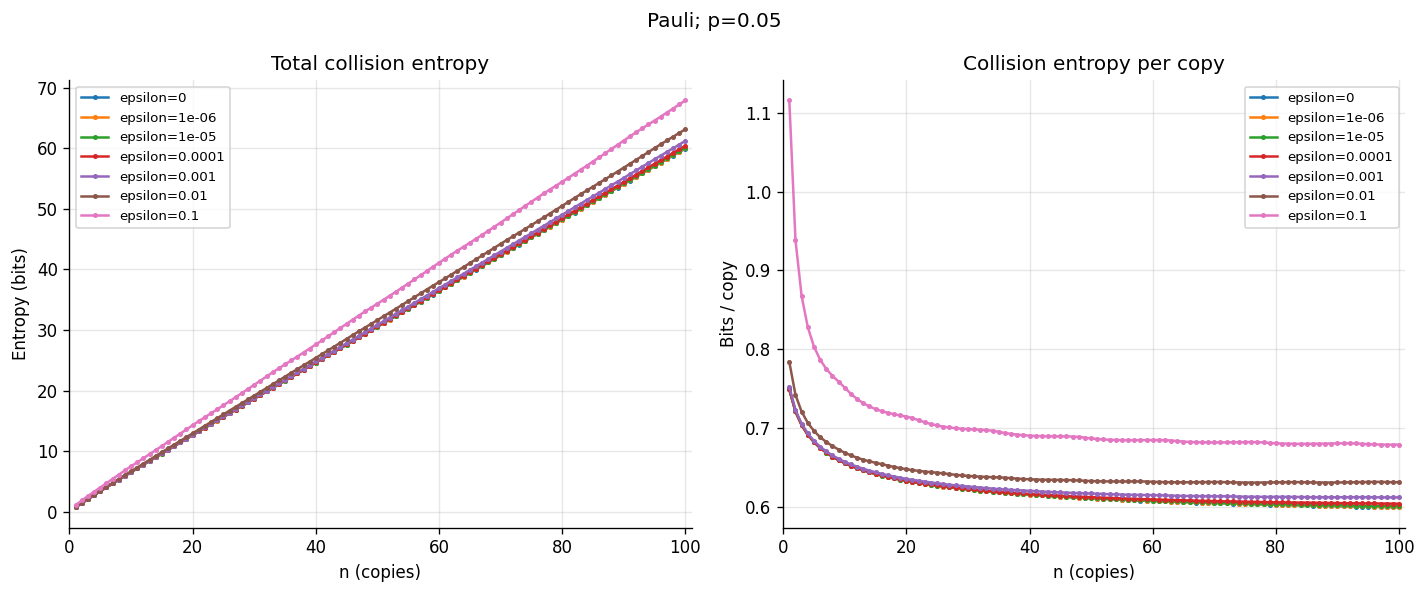

In [11]:
# @title 15. Quantum Eve: Plot Collision Entropy
DOT_SIZE = 2
X_LIMITS = (0, 101)
quantum = successful_results(collision_results, 'Quantum collision entropy')
for p, group in quantum.groupby('p'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for epsilon, curve in group.groupby('epsilon'):
        curve = curve.sort_values('n')
        label = f'epsilon={epsilon:g}'
        axes[0].plot(curve['n'], curve['H_bits'], 'o-', label=label, markersize=DOT_SIZE)
        axes[1].plot(curve['n'], curve['bits_per_copy'], 'o-', label=label, markersize=DOT_SIZE)
    axes[0].set(title='Total collision entropy', xlabel='n (copies)', ylabel='Entropy (bits)')
    axes[1].set(title='Collision entropy per copy', xlabel='n (copies)', ylabel='Bits / copy')
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        ax.set_xlim(X_LIMITS)
    fig.suptitle(f'Pauli; p={p:g}')
    fig.tight_layout()
    save_figure(fig, f'collision_entropy_p{p:g}')


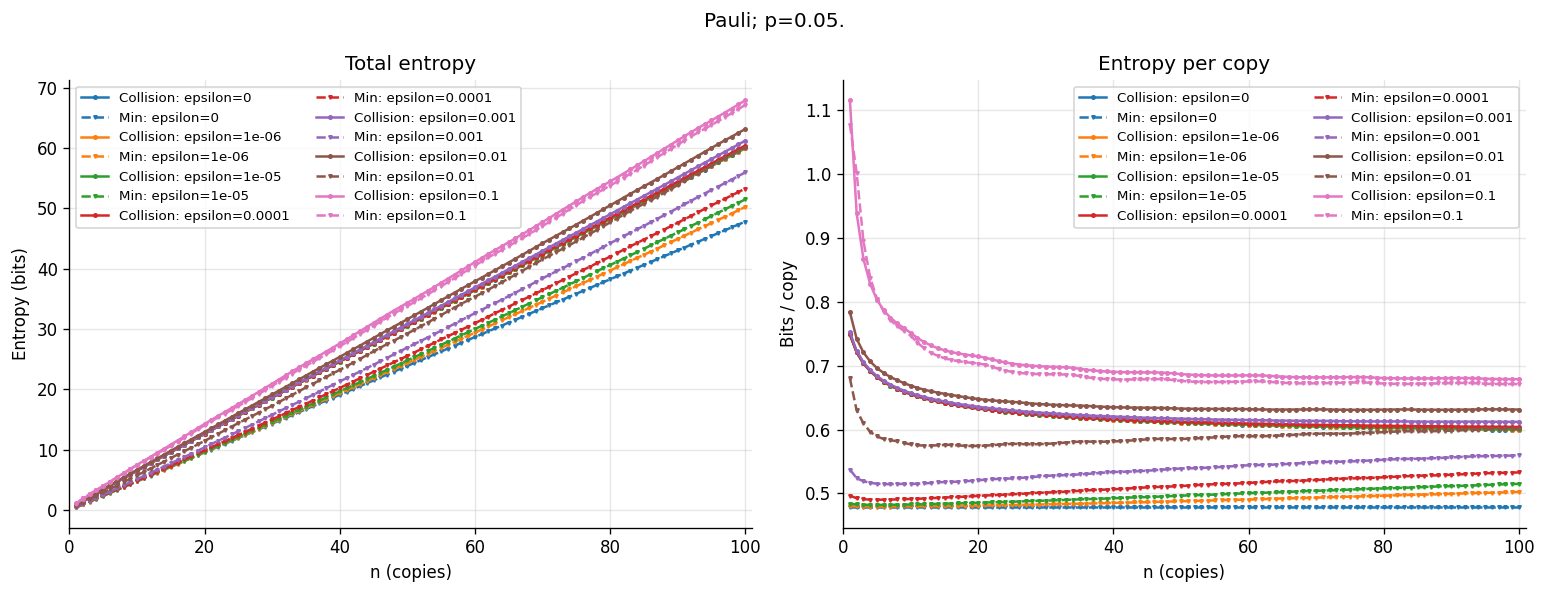

In [12]:
# @title 16. Collision Entropy vs Min-Entropy: Comparison Plots
quantum = successful_results(collision_results, 'Quantum collision entropy')
minimum = successful_results(min_entropy_results, 'Smooth min-entropy')
comparison = quantum.merge(minimum, on=['p', 'epsilon', 'n'], suffixes=('_collision', '_min'))
comparison['difference_total'] = comparison['H_bits_collision'] - comparison['H_bits_min']
comparison['difference_per_copy'] = comparison['difference_total'] / comparison['n']
comparison.to_csv(OUTPUT_DIR / 'collision_min_comparison.csv', index=False)

X_LIMITS = (0, 101)

for p, group in comparison.groupby('p'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for idx, (epsilon, curve) in enumerate(group.groupby('epsilon')):
        curve = curve.sort_values('n')
        color = plt.cm.tab10.colors[idx % 10]
        label_coll = f'Collision: epsilon={epsilon:g}'
        label_min = f'Min: epsilon={epsilon:g}'
        axes[0].plot(curve['n'], curve['H_bits_collision'], 'o-', color=color, label=label_coll, markersize=DOT_SIZE)
        axes[1].plot(curve['n'], curve['bits_per_copy_collision'], 'o-', color=color, label=label_coll, markersize=DOT_SIZE)
        axes[0].plot(curve['n'], curve['H_bits_min'], 'v--', color=color, label=label_min, markersize=DOT_SIZE)
        axes[1].plot(curve['n'], curve['bits_per_copy_min'], 'v--', color=color, label=label_min, markersize=DOT_SIZE)
    axes[0].set(title='Total entropy', xlabel='n (copies)', ylabel='Entropy (bits)')
    axes[1].set(title='Entropy per copy', xlabel='n (copies)', ylabel='Bits / copy')
    for index, ax in enumerate(axes):
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, ncol=2, loc='upper left' if index == 0 else 'upper right')
        ax.set_xlim(X_LIMITS)
    fig.suptitle(f'Pauli; p={p:g}.')
    fig.tight_layout()
    save_figure(fig, f'entropy_comparison_p{p:g}')


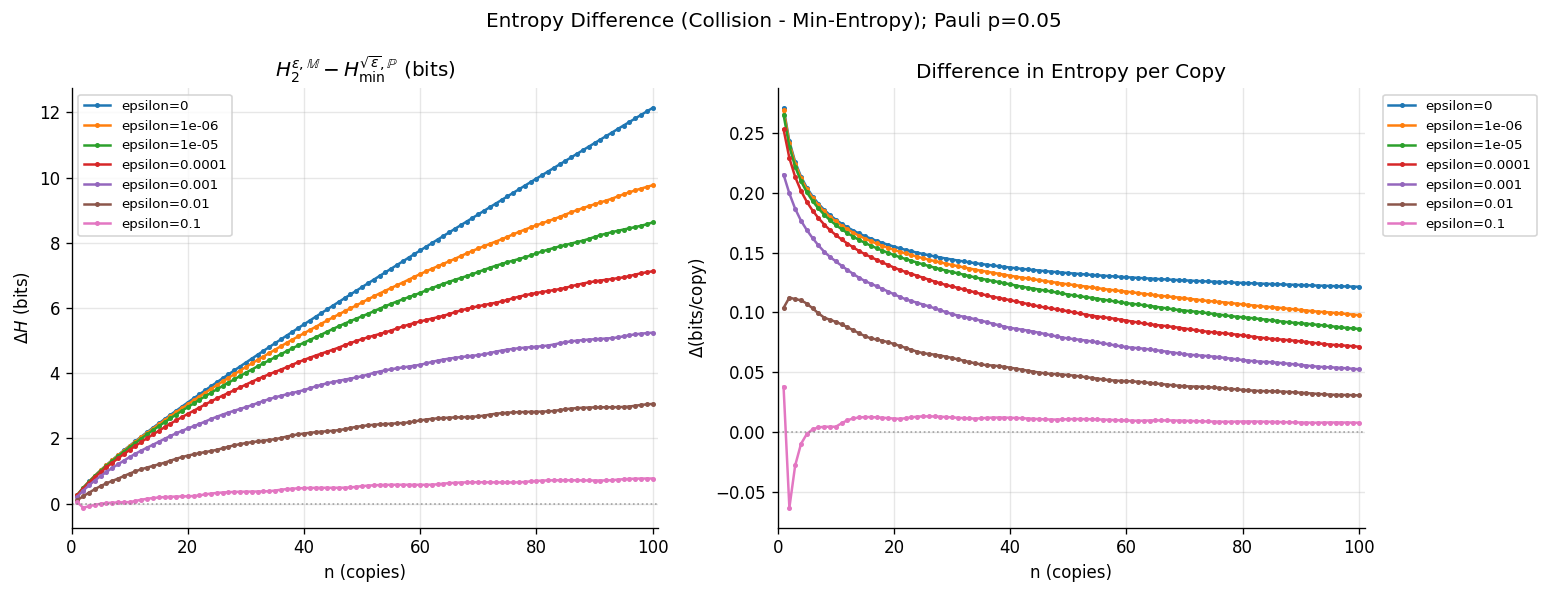

In [13]:
# @title 17. Collision Entropy vs Min-Entropy: Difference Plots
X_LIMITS = (0, 101)

for p, group in comparison.groupby('p'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for idx, (epsilon, curve) in enumerate(group.groupby('epsilon')):
        curve = curve.sort_values('n')
        color = plt.cm.tab10.colors[idx % 10]
        label = f'epsilon={epsilon:g}'
        axes[0].plot(curve['n'], curve['difference_total'], 'o-', color=color, label=label, markersize=DOT_SIZE)
        axes[1].plot(curve['n'], curve['difference_per_copy'], 'o-', color=color, label=label, markersize=DOT_SIZE)
    axes[0].set(
        title=r'$H_2^{\varepsilon, \mathbb{M}} - H_{\min}^{\sqrt{\varepsilon}, \mathbb{P}}$ (bits)',
        xlabel='n (copies)', ylabel=r'$\Delta H$ (bits)')
    axes[1].set(
        title='Difference in Entropy per Copy',
        xlabel='n (copies)', ylabel=r'$\Delta (\mathrm{bits / copy})$')
    for index, ax in enumerate(axes):
        ax.axhline(0, color='gray', linestyle=':', linewidth=1, alpha=0.7)
        ax.grid(alpha=0.3)
        ax.set_xlim(X_LIMITS)
        if index == 0:
            ax.legend(fontsize=8, loc='upper left')
        else:
            ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
    fig.suptitle(f'Entropy Difference (Collision - Min-Entropy); Pauli p={p:g}')
    fig.tight_layout()
    save_figure(fig, f'entropy_difference_p{p:g}')


# @title 18. Reading and Extending the Collision vs Min-Entropy Results
## Reading and extending the results

- `collision_results`: measured smooth collision entropy for this CQ state.
- `min_entropy_results`: smooth min-entropy with the explicitly stored radii.
- `comparison`: collision-minus-min-entropy differences at matching p, epsilon, and n.
- CSV checkpoints are written after each point. Set `RESUME=False` to recompute
  and change `OUTPUT_DIR` to choose where new runs save results.

Both entropy result tables use `H_bits` for total entropy and
`bits_per_copy` for the rate. Min-entropy uses **delta = sqrt(epsilon)**, so
its `radius_squared` equals epsilon. The merged comparison table distinguishes
the two quantities as `H_bits_collision` and `H_bits_min`, with corresponding
`bits_per_copy_collision` and `bits_per_copy_min` columns.
The legend's epsilon is the original notebook's comparison parameter, as shown
explicitly in the difference plot's mathematical title. The smoothing definitions
remain different even when their numeric parameters match.

At epsilon = 0, the min-entropy rate is constant in n. Subnormalized smooth
states can yield entropy slightly above n at endpoint parameters. The collision
solver retains collective variables across copies in a matrix of size n+1.
Its default numerical guard is n <= 20; the scalar min-entropy guard is n <= 100.
Full baseline matrices are restricted to n <= 2. These guards can be edited,
but larger-copy runs require checks of conditioning and feasibility residuals.

In Colab, generated files default to `MyDrive/pauli_entropy_results`. Mounting
Drive saves these files; save the notebook itself with **File > Save a copy in Drive**.
Set `SAVE_TO_GOOGLE_DRIVE=False` to use the temporary runtime folder instead.
Keep `RUN_VALIDATION=False` for routine sweeps after validating the formulation.

Some near-boundary baseline solves report `optimal_inaccurate` but pass the
stated comparison tolerances. These are floating-point numerical evaluations.
All results assume independent copies, uniform classical input bits, and no
additional public communication. All logarithms are base 2.


In [ ]:
# @title 19. Cluster Settings, Python/PBS Export, and GitHub Upload
import ast
import importlib.util
import json
import os
import re
import shlex
import shutil
import subprocess
import tempfile
from pathlib import Path

# Workflow: run in Colab -> export to GitHub -> pull/run on cluster -> push CSV/PNG results.
# This cell can also run by itself: it reads code and settings from the open notebook.
# Add GITHUB_TOKEN to Colab Secrets and grant this notebook access (repository Contents: write).
# Create the GitHub repository first; an empty repository is supported.
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False

EXPORT_RESULTS_DIR = Path(globals().get(
    'OUTPUT_DIR', '/content/drive/MyDrive/pauli_entropy_results' if IN_COLAB else 'pauli_entropy_results'))
EXPORT_DIR = EXPORT_RESULTS_DIR / 'cluster_export'
NOTEBOOK_PATH = Path('pauli_combined_entropy.ipynb')  # Set the notebook path when running locally.
EXPORT_CALCULATIONS = ['collision', 'min_entropy']
INCLUDE_SAVED_RESULTS = True  # CSV/PNG files under EXPORT_RESULTS_DIR, excluding cluster_export.
OVERWRITE_GITHUB_RESULTS = False  # Preserve results already pushed from the cluster.
PUSH_TO_GITHUB = True  # Set False to generate the files without uploading.
GITHUB_USER = 'CatUwUKitty'
GITHUB_REPO = 'pauliEntropy'
GITHUB_BRANCH = 'main'
GITHUB_TOKEN_SECRET = 'GITHUB_TOKEN'
PBS_CONFIG = {
    'project': 'Entropy', 'queue': 'parallel',
    'ncpus': 12, 'mem': '64gb', 'walltime': '240:00:00',
    'job_name': 'PauliEntropy', 'module_python': 'Python-3.10.4',
    'venv_path': '${HOME}/myenv',
    'mosek_lic_path': '${HOME}/mosek/mosek.lic',
    'script_args': '',  # Example: '--p 0.05 --collision-epsilon 0.001 --n 1 2 3'
    'email': '',
}

EXPORT_HEADER = '''# Generated from pauli_combined_entropy.ipynb; edit the notebook and export again.
import argparse
import hashlib
import itertools
import json
import math
import os
import sys
import time
import warnings
from pathlib import Path
from functools import lru_cache
from math import comb, lgamma
import numpy as np
import pandas as pd
import cvxpy as cp
from scipy.special import gammaln, logsumexp
from scipy.stats import binom

if 'MOSEKLM_LICENSE_FILE' not in os.environ:
    for candidate in (Path.home() / 'mosek' / 'mosek.lic', Path.home() / '.mosek' / 'mosek.lic'):
        if candidate.is_file():
            os.environ['MOSEKLM_LICENSE_FILE'] = str(candidate)
            break
'''

EXPORT_CLI = '''
def parse_arguments():
    parser = argparse.ArgumentParser(description='Checkpointed Pauli entropy parameter sweeps.')
    parser.add_argument('--calculations', nargs='+', choices=['collision', 'min_entropy'],
                        default=DEFAULT_CALCULATIONS)
    parser.add_argument('--p', nargs='+', type=float, help='Pauli state probabilities')
    parser.add_argument('--collision-epsilon', nargs='+', type=float,
                        help='Collision epsilon; also sets min-entropy radius squared unless overridden')
    parser.add_argument('--min-entropy-epsilon', nargs='+', type=float,
                        help='Optional independent min-entropy squared purified-distance radii')
    parser.add_argument('--n', nargs='+', type=int, help='Copy counts for both entropies')
    parser.add_argument('--solver', type=str.upper, choices=['MOSEK', 'CLARABEL', 'SCS'])
    parser.add_argument('--tol', type=float)
    parser.add_argument('--max-collision-copies', type=int)
    parser.add_argument('--max-scalar-min-copies', type=int)
    parser.add_argument('--output-dir', help='Default: pauli_entropy_results, relative to working directory')
    resume = parser.add_mutually_exclusive_group()
    resume.add_argument('--resume', dest='resume', action='store_true')
    resume.add_argument('--no-resume', dest='resume', action='store_false')
    errors = parser.add_mutually_exclusive_group()
    errors.add_argument('--fail-fast', dest='continue_on_error', action='store_false')
    errors.add_argument('--continue-on-error', dest='continue_on_error', action='store_true')
    parser.set_defaults(resume=None, continue_on_error=None)
    return parser.parse_args()


def apply_cli_arguments(args):
    global P_VALUES, COLLISION_EPSILON_VALUES, MIN_ENTROPY_EPSILON_VALUES
    global COLLISION_N_VALUES, MIN_ENTROPY_N_VALUES, COLLISION_SOLVER, COLLISION_TOL
    global MAX_COLLISION_COPIES, MAX_SCALAR_MIN_COPIES, OUTPUT_DIR, RESUME, CONTINUE_ON_ERROR
    if args.p is not None:
        P_VALUES = args.p
    if args.collision_epsilon is not None:
        COLLISION_EPSILON_VALUES = args.collision_epsilon
        MIN_ENTROPY_EPSILON_VALUES = list(args.collision_epsilon)
    if args.min_entropy_epsilon is not None:
        MIN_ENTROPY_EPSILON_VALUES = args.min_entropy_epsilon
    if args.n is not None:
        COLLISION_N_VALUES = list(args.n)
        MIN_ENTROPY_N_VALUES = list(args.n)
    if args.solver is not None:
        COLLISION_SOLVER = args.solver
    if args.tol is not None:
        COLLISION_TOL = args.tol
    if args.max_collision_copies is not None:
        MAX_COLLISION_COPIES = args.max_collision_copies
    if args.max_scalar_min_copies is not None:
        MAX_SCALAR_MIN_COPIES = args.max_scalar_min_copies
    if args.output_dir is not None:
        OUTPUT_DIR = Path(args.output_dir)
    if args.resume is not None:
        RESUME = args.resume
    if args.continue_on_error is not None:
        CONTINUE_ON_ERROR = args.continue_on_error
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
'''


def read_notebook_for_export(path):
    if IN_COLAB:
        from google.colab import _message
        response = _message.blocking_request('get_ipynb')
        if not isinstance(response, dict) or 'ipynb' not in response:
            raise RuntimeError('Could not read the open Colab notebook. Save it and retry.')
        notebook = response['ipynb']
    else:
        path = Path(path)
        if not path.is_file():
            raise FileNotFoundError(f'Set NOTEBOOK_PATH to the saved Pauli notebook: {path}')
        notebook = json.loads(path.read_text(encoding='utf-8-sig'))
    if isinstance(notebook, str):
        notebook = json.loads(notebook)
    if not isinstance(notebook, dict) or not isinstance(notebook.get('cells'), list):
        raise ValueError('The notebook export response must contain a cells list.')
    return notebook


def get_export_role(cell):
    title_roles = {
        'Parameters and Solver Settings': 'settings',
        'Shared Validation, Checkpoint, and Plot Helpers': 'helpers',
        'State Constructors and Reference Calculations': 'states',
        'Permutation-Reduced Collision Entropy Solver': 'collision',
        'Baseline Collision Entropy Solver': 'baseline',
        'Scalar, Conic, and Baseline Min-Entropy Solvers': 'minimum',
        'Run Quantum Entropy Sweeps and Save Checkpoints': 'runs',
    }
    role = cell.get('metadata', {}).get('pauli_export_role')
    if role in title_roles.values():
        return role
    source = cell.get('source', '')
    source = source if isinstance(source, str) else ''.join(source)
    for line in source.splitlines():
        match = re.match(r'^\s*#\s*@title\s+(.+?)\s*$', line)
        if match:
            title = re.sub(r'^\d+[.)]\s*', '', match.group(1).replace('**', '').strip())
            return title_roles.get(title)
    return None


def build_cluster_script(notebook, calculations):
    permitted = {'collision', 'min_entropy'}
    if not calculations or not set(calculations) <= permitted:
        raise ValueError(f'Choose calculations from {sorted(permitted)}.')
    trees = {}
    for cell in notebook['cells']:
        role = get_export_role(cell) if cell.get('cell_type') == 'code' else None
        if role is None:
            continue
        if role in trees:
            raise ValueError(f'Duplicate export role: {role}. Remove the duplicate calculation cell.')
        source = cell.get('source', '')
        trees[role] = ast.parse(source if isinstance(source, str) else ''.join(source))
    missing = {'settings', 'helpers', 'states', 'collision', 'baseline', 'minimum', 'runs'} - trees.keys()
    if missing:
        raise ValueError(f'Missing export roles: {sorted(missing)}. Retain the original # @title lines.')

    settings = []
    for node in trees['settings'].body:
        if not isinstance(node, (ast.Assign, ast.AnnAssign)):
            continue  # Folder creation and display happen after command-line overrides.
        targets = node.targets if isinstance(node, ast.Assign) else [node.target]
        names = {target.id for target in targets if isinstance(target, ast.Name)}
        if 'OUTPUT_DIR' in names:
            node.value = ast.parse("Path('pauli_entropy_results')", mode='eval').body
        elif 'RUN_VALIDATION' in names:
            node.value = ast.Constant(False)
        settings.append(node)
    definitions = []
    for role in ('helpers', 'states', 'collision', 'baseline', 'minimum', 'runs'):
        definitions.extend(node for node in trees[role].body
                           if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))
                           and node.name != 'save_figure')
    reference = [node for node in trees['states'].body if isinstance(node, ast.Assign)
                 and any(isinstance(t, ast.Name) and t.id == 'reference_results' for t in node.targets)]
    if len(reference) != 1:
        raise ValueError('Expected one reference_results assignment in the state-construction cell.')
    runs = {}
    for calculation in ('collision', 'min_entropy'):
        matches = [node for node in trees['runs'].body if isinstance(node, ast.Assign)
                   and any(isinstance(t, ast.Name) and t.id == calculation + '_results'
                           for t in node.targets)]
        if len(matches) != 1:
            raise ValueError(f'Expected one {calculation}_results assignment in the sweep cell.')
        runs[calculation] = ast.unparse(matches[0])

    script = EXPORT_HEADER + '\nDEFAULT_CALCULATIONS = ' + repr(list(calculations)) + '\n\n'
    script += ast.unparse(ast.Module(body=settings + definitions, type_ignores=[])) + '\n'
    script += EXPORT_CLI + '\n\ndef main():\n'
    script += '    args = parse_arguments()\n    apply_cli_arguments(args)\n    any_errors = False\n'
    script += '\n'.join('    ' + line for line in ast.unparse(reference[0]).splitlines()) + '\n'
    script += "    reference_results.to_csv(OUTPUT_DIR / 'reference_results.csv', index=False)\n"
    for calculation, action in runs.items():
        script += f'    if {calculation!r} in args.calculations:\n'
        script += '\n'.join('        ' + line for line in action.splitlines()) + '\n'
        script += f"        print_result_table({calculation}_results, ['p', 'epsilon', 'n', 'H_bits', 'bits_per_copy', 'radius'])\n"
        script += f"        if ({calculation}_results['run_status'] == 'error').any():\n            any_errors = True\n"
    script += '    return 1 if any_errors else 0\n\nif __name__ == "__main__":\n    sys.exit(main())\n'
    compile(script, 'run_cluster.py', 'exec')
    return script


def generate_pbs_script(config):
    notifications = f"#PBS -m ae\n#PBS -M {config['email']}\n" if config['email'] else ''
    return f'''#!/bin/bash
#PBS -P {config['project']}
#PBS -q {config['queue']}
#PBS -l select=1:ncpus={config['ncpus']}:mem={config['mem']}
#PBS -l walltime={config['walltime']}
#PBS -j oe
#PBS -N {config['job_name']}
{notifications}
set -eo pipefail
cd "${{PBS_O_WORKDIR}}"
export MALLOC_ARENA_MAX={config['ncpus']}
export OMP_NUM_THREADS={config['ncpus']}
export OPENBLAS_NUM_THREADS={config['ncpus']}
export MKL_NUM_THREADS={config['ncpus']}
export NUMEXPR_NUM_THREADS={config['ncpus']}
source /app1/ebenv {config['module_python']}
unset PYTHONPATH
source "{config['venv_path']}/bin/activate"
python -m pip install -r requirements.txt
export MOSEKLM_LICENSE_FILE="{config['mosek_lic_path']}"
exec python -u run_cluster.py {config['script_args']}
'''


def generate_results_uploader():
    return f'''#!/usr/bin/env python3
"""Run from the cluster checkout after the job: python push_results.py."""
import argparse
import subprocess
from pathlib import Path

BRANCH = {GITHUB_BRANCH!r}

def git(*args, capture=False):
    result = subprocess.run(['git', *args], check=True, text=True,
                            stdout=subprocess.PIPE if capture else None)
    return result.stdout.strip() if capture else None

def main():
    parser = argparse.ArgumentParser(description='Commit and push Pauli CSV/PNG results.')
    parser.add_argument('--results-dir', default='pauli_entropy_results')
    parser.add_argument('--message', default='Update Pauli entropy results from cluster')
    args = parser.parse_args()
    root = Path(git('rev-parse', '--show-toplevel', capture=True)).resolve()
    directory = Path(args.results_dir).resolve()
    if not directory.is_relative_to(root) or directory == root:
        raise SystemExit('Choose a results folder inside this Git checkout.')
    if git('branch', '--show-current', capture=True) != BRANCH:
        raise SystemExit(f'Check out {{BRANCH}} before pushing results.')
    if git('diff', '--cached', '--name-only', capture=True):
        raise SystemExit('Commit or unstage existing staged changes before pushing results.')
    files = sorted(path.relative_to(root).as_posix() for path in directory.rglob('*')
                   if path.is_file() and path.suffix.lower() in ('.csv', '.png')
                   and 'cluster_export' not in path.relative_to(directory).parts
                   and path.resolve().is_relative_to(root))
    if not files:
        raise SystemExit(f'No CSV/PNG results found in {{directory}}.')
    # Small batches avoid command-line limits for large sweeps.
    for offset in range(0, len(files), 100):
        git('-C', str(root), 'add', '--', *files[offset:offset + 100])
    if git('diff', '--cached', '--name-only', capture=True):
        git('commit', '-m', args.message)
    git('push', 'origin', BRANCH)

if __name__ == '__main__':
    main()
'''


def generate_workflow_readme():
    remote = f'https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git'
    return f'''# Pauli entropy: Colab -> GitHub -> cluster -> GitHub

1. Edit/run `pauli_combined_entropy.ipynb` in Colab. Add `GITHUB_TOKEN` to
   Colab Secrets, grant the notebook access, and give the token Contents: write
   permission for `{GITHUB_USER}/{GITHUB_REPO}`. Create the repository first.
2. Run the final exporter cell. It saves the current notebook (including outputs),
   `run_cluster.py`, `submit.pbs`, `requirements.txt`, `push_results.py`, this guide,
   and existing CSV/PNG results under `pauli_entropy_results/`. Existing GitHub
   result files are preserved; set OVERWRITE_GITHUB_RESULTS=True in the exporter
   only when you intend to replace them with the Colab versions.
   You can run the exporter alone without repeating the sweeps; it uses notebook
   source settings. If needed, set EXPORT_RESULTS_DIR to your saved results folder.
3. On the cluster, clone once or update your existing checkout:

   ```bash
   git clone --branch {shlex.quote(GITHUB_BRANCH)} {shlex.quote(remote)}
   cd {shlex.quote(GITHUB_REPO)}
   # For later exports, from this checkout:
   git pull --ff-only origin {shlex.quote(GITHUB_BRANCH)}
   ```

4. Review `submit.pbs`: project/queue/resources, Python module, virtual environment,
   and MOSEK license path are copied from the Werner setup. Create the virtual
   environment once if necessary (`python3 -m venv ~/myenv`, using the cluster's
   Python module). Dependencies are installed by the PBS job. Keep the MOSEK
   license on the cluster, outside this repository.

   ```bash
   qsub submit.pbs
   # Or, with dependencies installed in your active environment:
   python run_cluster.py --p 0.05 --collision-epsilon 0.001 --n 1 2 3 --solver CLARABEL
   python run_cluster.py --help
   ```

   The runner uses the notebook's saved parameters unless overridden. Changing
   `--collision-epsilon` also changes the min-entropy squared radius; use
   `--min-entropy-epsilon` for an independent override. It excludes Colab setup,
   plots, baseline-validation runs, and the exporter. Existing successful CSV
   checkpoints are reused when RESUME is enabled in the notebook or via `--resume`.
   Failed points are retried; a run with errors exits nonzero.

5. After the job completes, push the data from the cluster checkout:

   ```bash
   git config user.name {shlex.quote(GITHUB_USER)}
   git config user.email {shlex.quote(GITHUB_USER + '@users.noreply.github.com')}
   python push_results.py
   # If you chose a custom output folder inside this checkout:
   python push_results.py --results-dir my_results
   ```

   Configure Git authentication on the cluster separately (SSH or a credential
   helper). The exporter does not save the Colab token. The upload helper stages
   only CSV/PNG results and requires other staged changes to be resolved first.
   If Git rejects a push because the remote advanced, reconcile it with
   `git pull --rebase origin {GITHUB_BRANCH}`, then rerun the upload helper.
   Do not push results while a job is still updating checkpoint files.
   Pull the repository again to bring the results back to your other machines.

The exporter generates files before contacting GitHub and never submits a job.
Set `PUSH_TO_GITHUB = False` to export locally. Solver settings and numerical
formulations remain in the notebook; edit them there and export again.
'''


def push_exported_files(file_mapping):
    if IN_COLAB:
        from google.colab import userdata
        token = userdata.get(GITHUB_TOKEN_SECRET)
    else:
        token = os.environ.get(GITHUB_TOKEN_SECRET)
    if not token:
        raise ValueError(f'Configure {GITHUB_TOKEN_SECRET} before enabling GitHub upload. Files were exported locally.')
    remote = f'https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git'
    authenticated_remote = remote.replace('https://', 'https://x-access-token@')
    checkout = EXPORT_DIR / 'github_checkout'
    with tempfile.TemporaryDirectory(prefix='git_auth_', dir=EXPORT_DIR) as auth_dir:
        askpass = Path(auth_dir) / ('git_askpass.cmd' if os.name == 'nt' else 'git_askpass.sh')
        if os.name == 'nt':
            askpass.write_text('@echo off\n@echo %PAULI_GIT_TOKEN%\n', encoding='ascii')
        else:
            askpass.write_text('#!/bin/sh\nprintf "%s\\n" "$PAULI_GIT_TOKEN"\n', encoding='ascii')
            askpass.chmod(0o700)
        env = dict(os.environ, PAULI_GIT_TOKEN=token,
                   GIT_ASKPASS=str(askpass.resolve()), GIT_TERMINAL_PROMPT='0')

        def git(arguments, cwd=None):
            result = subprocess.run(['git', *arguments], cwd=cwd, env=env, capture_output=True, text=True)
            if result.returncode:
                details = (result.stderr or result.stdout).replace(token, '[REDACTED_TOKEN]')
                raise RuntimeError(f'Git operation failed. Exported files remain in {EXPORT_DIR}.\n{details}')
            return result.stdout

        git(['check-ref-format', '--branch', GITHUB_BRANCH])
        branch_exists = bool(git(['ls-remote', '--heads', authenticated_remote,
                                 'refs/heads/' + GITHUB_BRANCH]).strip())
        if checkout.exists():
            if git(['remote', 'get-url', 'origin'], checkout).strip() != authenticated_remote:
                raise RuntimeError('Existing export checkout has another remote; choose a new EXPORT_DIR.')
            if git(['status', '--porcelain'], checkout).strip():
                raise RuntimeError('Export checkout has uncommitted changes; resolve them before uploading.')
            git(['fetch', 'origin'], checkout)
            git(['checkout', GITHUB_BRANCH], checkout)
            if branch_exists:
                git(['pull', '--ff-only', 'origin', GITHUB_BRANCH], checkout)
        else:
            branch_args = ['--branch', GITHUB_BRANCH] if branch_exists else []
            git(['clone', *branch_args, authenticated_remote, str(checkout.resolve())])
            if not branch_exists:
                git(['checkout', '-B', GITHUB_BRANCH], checkout)
        git(['config', 'user.name', GITHUB_USER], checkout)
        git(['config', 'user.email', f'{GITHUB_USER}@users.noreply.github.com'], checkout)
        for local_file, repo_name in file_mapping.items():
            destination = checkout / repo_name
            if (repo_name.startswith('pauli_entropy_results/') and destination.exists()
                    and not OVERWRITE_GITHUB_RESULTS):
                print(f'Preserved existing GitHub result: {repo_name}')
                continue
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(local_file, destination)
            git(['add', '--', repo_name], checkout)
        if git(['diff', '--cached', '--name-only'], checkout).strip():
            git(['commit', '-m', 'Update Pauli notebook, cluster runner, and saved results'], checkout)
        git(['push', 'origin', GITHUB_BRANCH], checkout)
    print(f'Uploaded {len(file_mapping)} files to {remote} [{GITHUB_BRANCH}]')


EXPORT_DIR.mkdir(parents=True, exist_ok=True)
notebook_for_export = read_notebook_for_export(NOTEBOOK_PATH)
export_contents = {
    'run_cluster.py': build_cluster_script(notebook_for_export, EXPORT_CALCULATIONS),
    'submit.pbs': generate_pbs_script(PBS_CONFIG),
    'requirements.txt': 'numpy\npandas\nscipy\ncvxpy\nclarabel\nmatplotlib\nmosek\n',
    'push_results.py': generate_results_uploader(),
    'README_cluster.md': generate_workflow_readme(),
    'pauli_combined_entropy.ipynb': json.dumps(notebook_for_export, ensure_ascii=False, indent=2) + '\n',
}
exported_files = {}
for repo_name, content in export_contents.items():
    destination = EXPORT_DIR / repo_name
    destination.write_text(content, encoding='utf-8', newline='\n')
    exported_files[destination] = repo_name
    print(f'Wrote {destination}')
if INCLUDE_SAVED_RESULTS and EXPORT_RESULTS_DIR.is_dir():
    for result_path in sorted(EXPORT_RESULTS_DIR.rglob('*')):
        if (result_path.is_file() and result_path.suffix.lower() in ('.csv', '.png')
                and not result_path.resolve().is_relative_to(EXPORT_DIR.resolve())):
            relative = result_path.relative_to(EXPORT_RESULTS_DIR)
            destination = EXPORT_DIR / 'pauli_entropy_results' / relative
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(result_path, destination)
            exported_files[destination] = (Path('pauli_entropy_results') / relative).as_posix()
print(f'Export ready: {len(exported_files)} files in {EXPORT_DIR}')
if PUSH_TO_GITHUB:
    push_exported_files(exported_files)
else:
    print('GitHub upload disabled. Set PUSH_TO_GITHUB=True to upload the generated export.')
